<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch5_hougen_watson_constraints.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Hougen-Watson estimation with bounds $\underline{\theta}\leq\theta\leq\overline{\theta}$
(Victor Z and Leo Gonzalez, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\underline{\theta}$, $\overline{\theta}$ | `theta_lb`, `theta_ub` | bounds $(0,\dots,0)$ and $(2,\dots,2)$ |
| $\nabla_\theta\mathbf{m}(\hat{\theta})$ | `J` | Jacobian returned by the solver |
| $\mathcal{H}(\hat{\theta})\approx\nabla_\theta\mathbf{m}^T\nabla_\theta\mathbf{m}$ | `H` | Gauss-Newton Hessian |
| $\lambda$ | `lam` | eigenvalues of $\mathcal{H}$ |
| $\mathrm{Cov}[\hat{\theta}]$, $\mathbb{V}[\hat{\theta}]$ | `Cov_theta`, `V_theta` | covariance and variances |

**Note:** This notebook reproduces Example 5.13 (Section 5.4) of *Statistics for Chemical Engineers*: estimating the Hougen-Watson model with physical bounds on the parameters.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

data = np.loadtxt(path+'Data/hougenwatson.dat')
X, y = data[:, :3], data[:, -1]
S = len(y)

def m(theta, X):
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    return (theta[0]*x2 - x3/theta[4]) / (1 + theta[1]*x1 + theta[2]*x2 + theta[3]*x3)

def residual(theta):
    return m(theta, X) - y

Unconstrained problem from the bad initial guess $\theta=(-1,\dots,-1)$:

In [3]:
sol = least_squares(residual, -np.ones(5), method='trf')
print("unconstrained theta_hat =", np.round(sol.x, 2))

unconstrained theta_hat = [-2267.65  -114.05   -80.49  -196.14    -0.  ]


Constrained problem with $\underline{\theta}=0$ and $\overline{\theta}=2$:

constrained theta_hat = [1.25 0.06 0.04 0.11 1.19]


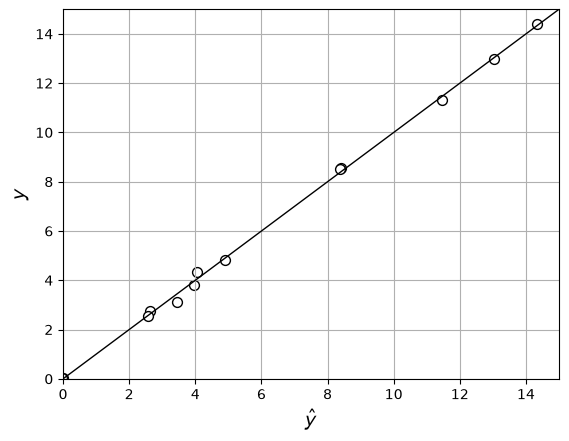

In [4]:
theta_lb, theta_ub = np.zeros(5), 2 * np.ones(5)
sol = least_squares(residual, np.ones(5), bounds=(theta_lb, theta_ub), method='trf')
theta_hat = sol.x
print("constrained theta_hat =", np.round(theta_hat, 2))

y_hat = m(theta_hat, X)
plt.plot([0, 15], [0, 15], 'k-', linewidth=1)
plt.scatter(y_hat, y, marker='o', color='w', edgecolor='k', s=50)
plt.xlabel(r'$\hat{y}$', fontsize=14); plt.ylabel('$y$', fontsize=14)
plt.axis([0, 15, 0, 15]); plt.grid(True)
plt.show()

Gauss-Newton Hessian, its eigenvalues, and $\mathrm{Cov}[\hat{\theta}]=\mathcal{H}(\hat{\theta})^{-1}\hat{\sigma}^2$.

In [5]:
J = sol.jac
H = J.T @ J
lam = np.linalg.eigvalsh(H)[::-1]
sigma2_hat = np.var(y_hat - y, ddof=1)
Cov_theta = np.linalg.inv(H) * sigma2_hat
V_theta = np.diag(Cov_theta)
np.set_printoptions(precision=3)
print("H =\n", H)
print("eigenvalues of H:", lam)
print("V[theta_hat] =", V_theta)

H =
 [[ 6.196e+02 -4.309e+03 -6.351e+03 -9.411e+02  9.998e+01]
 [-4.309e+03  3.782e+04  4.457e+04  4.726e+03 -4.342e+02]
 [-6.351e+03  4.457e+04  7.510e+04  9.333e+03 -6.631e+02]
 [-9.411e+02  4.726e+03  9.333e+03  2.151e+03 -1.937e+02]
 [ 9.998e+01 -4.342e+02 -6.631e+02 -1.937e+02  3.934e+01]]
eigenvalues of H: [1.064e+05 8.362e+03 9.531e+02 3.534e+01 2.561e-02]
V[theta_hat] = [0.501 0.001 0.001 0.004 0.466]


**Note:** As in the book, the constraints keep the estimates physical, the Hessian is well conditioned, and the parameter variances are small.